## Assignment 2


* Use Python as a programming language and finish this assignment
* Work is to be done individually for this assignment
* Students handing in similar work will both receive a grade of 0 and will face disciplinary actions
* Answers generated from AI (e.g., ChatGPT) will receive a grade of 0 and will face academic sanctions





data file: https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/advertising.csv

### Import libraries

In [25]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


In [26]:
import statsmodels.api as sm

### Part 1 Linear Regression

1.1 Please read data file (advertising.csv) into a dataframe

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/advertising.csv")
df.head()

,TV,Sales,Radio,Newspaper,City,State,Region
0,78.2,14.6,46.8,34.5,Philadelphia,PA,East
1,225.8,18.4,8.2,56.5,Chicago,IL,Midwest
2,163.3,16.9,31.6,52.9,New York,NY,East
3,39.5,10.8,41.1,5.8,Atlanta,GA,South
4,95.7,11.9,1.4,7.4,Atlanta,GA,South


1.2 Please get non-numerical column names: City, State and Region and drop non-numerical columns

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Sales      200 non-null    float64
 2   Radio      200 non-null    float64
 3   Newspaper  200 non-null    float64
 4   City       200 non-null    object 
 5   State      200 non-null    object 
 6   Region     200 non-null    object 
dtypes: float64(4), object(3)
memory usage: 11.1+ KB


In [5]:
df.drop(['City', 'State','Region'], axis = 1, inplace = True)
df.head()

,TV,Sales,Radio,Newspaper
0,78.2,14.6,46.8,34.5
1,225.8,18.4,8.2,56.5
2,163.3,16.9,31.6,52.9
3,39.5,10.8,41.1,5.8
4,95.7,11.9,1.4,7.4


1.3 Please set TV, Radio and Newspaper as independent variables and Sales as a Dependent Variable and show regression results

In [6]:
# Independent vairables X (all besides sales)
X = df.drop('Sales', axis = 1)

# Dependent variable y - Sales
y = df['Sales']

In [7]:
X.shape

(200, 3)

In [8]:
# Add constant (intercept)
X1 = sm.add_constant(X)

# Fit linear regression
model = sm.OLS(y, X1).fit()

# Regression results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        18:09:41   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

1.4 Please explain the regression results (for example, what does the coefficient before TV means?)

TV and Radio advertising have positive and statistically significant relationships with Sales (p < 0.01). Newspaper advertising also has a positive relationship with Sales, but it is not statistically significant.

**Interpretation of coefficients:** An additional USD 1,000 spent on TV advertising, while keeping Radio and Newspaper advertising budgets constant, is associated with an increase in predicted sales of approximately 54 units. An additional USD 1,000 spent on Radio advertising, while keeping TV and Newspaper advertising budgets constant, is associated with an increase in predicted sales of approximately 107 units.

**R-squared:** The R-squared value of 0.903 means that approximately 90.3% of the variation in Sales is explained by the independent variables.

1.5 Please set 70% training dataset and 30% test data and train linear regression model (random_state=42)

In [9]:
# 70% training set, 30% test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state = 42)

In [10]:
# Instantiate LinearRegression model
model = LinearRegression()

In [11]:
# Fit LinearRegression model
model.fit(X_train, y_train)

LinearRegression()

1.6 Please calculate the model performance (e.g. MSE) for the test set

In [12]:
# Calculate model performance for training set
y_train_predict = model.predict(X_train)
mse = mean_squared_error(y_train, y_train_predict)

print("Model performance for training set")
print("----------------------------------")
print("MSE is {}".format(round(mse,2)))


Model performance for training set
----------------------------------
MSE is 2.99


In [13]:
# Calculate model performance for test set
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)


print("Model performance for test set")
print("------------------------------")
print("MSE is {}".format(round(mse,2)))

Model performance for test set
------------------------------
MSE is 2.13


### 2. Logistic Regression


### Import Libaries

Data file: https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/breast_cancer_diagnosis.csv

In [14]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [15]:
import statsmodels.formula.api as smf

2.1 Please read data from file (breast_cancer_diagnosis.csv) into dataframe

In [16]:
df = pd.read_csv('https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/breast_cancer_diagnosis.csv')

In [17]:
df.head()

,id,name,radius,texture,perimeter,area,smoothness,compactness,concavity,symmetry,fractal_dimension,age,diagnosis
0,ID842302,Glynnis Munson,NaN,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.2419,0.07871,35,1
1,ID842517,Lana Behrer,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.1812,0.05667,27,1
2,ID84300903,Devondra Vanvalkenburgh,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.2069,0.05999,31,1
3,ID84348301,Glory Maravalle,NaN,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.2597,0.09744,49,1
4,ID84358402,Mellie Mccurdy,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.1809,0.05883,20,1


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 569 non-null    object 
 1   name               569 non-null    object 
 2   radius             498 non-null    float64
 3   texture            569 non-null    float64
 4   perimeter          569 non-null    float64
 5   area               569 non-null    float64
 6   smoothness         569 non-null    float64
 7   compactness        569 non-null    float64
 8   concavity          569 non-null    float64
 9   symmetry           569 non-null    float64
 10  fractal_dimension  569 non-null    float64
 11  age                569 non-null    int64  
 12  diagnosis          569 non-null    int64  
dtypes: float64(9), int64(2), object(2)
memory usage: 57.9+ KB


2.2 Please drop non-numeric variables and display first 10 rows of dataframe

In [19]:
df.drop(['id', 'name'], axis = 1, inplace = True)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   radius             498 non-null    float64
 1   texture            569 non-null    float64
 2   perimeter          569 non-null    float64
 3   area               569 non-null    float64
 4   smoothness         569 non-null    float64
 5   compactness        569 non-null    float64
 6   concavity          569 non-null    float64
 7   symmetry           569 non-null    float64
 8   fractal_dimension  569 non-null    float64
 9   age                569 non-null    int64  
 10  diagnosis          569 non-null    int64  
dtypes: float64(9), int64(2)
memory usage: 49.0 KB


2.3 Please check for missing values and replace missing values by mean of radius

In [21]:
# checking for missing values in all the columns
df.isnull().sum()

radius               71
texture               0
perimeter             0
area                  0
smoothness            0
compactness           0
concavity             0
symmetry              0
fractal_dimension     0
age                   0
diagnosis             0
dtype: int64

In [22]:
df['radius'] = df['radius'].fillna(df['radius'].mean())

In [23]:
df.isnull().sum()

radius               0
texture              0
perimeter            0
area                 0
smoothness           0
compactness          0
concavity            0
symmetry             0
fractal_dimension    0
age                  0
diagnosis            0
dtype: int64

2.4 Please use Diagnosis as a Dependent Variable and radius, texture, perimeter, area, smoothness, compactness, concavity, symmetry, fractal_dimension and age as independent variables and run logistic regression

In [24]:
# Independent vairables X (all besides diagnosis)
X = df.drop('diagnosis', axis = 1)

# Dependent variable y - diagnosis
y = df['diagnosis']

In [27]:
model = smf.logit(
    "diagnosis ~ radius + texture + perimeter + area + smoothness + compactness + concavity + symmetry + fractal_dimension + age",
    data=df
).fit()

print(model.summary())

Optimization terminated successfully.
         Current function value: 0.133337
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:              diagnosis   No. Observations:                  569
Model:                          Logit   Df Residuals:                      558
Method:                           MLE   Df Model:                           10
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.7981
Time:                        18:18:07   Log-Likelihood:                -75.869
converged:                       True   LL-Null:                       -375.72
Covariance Type:            nonrobust   LLR p-value:                2.039e-122
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           -16.6320     11.597     -1.434      0.152     -39.362       6.098
radius 

2.5 Please explain the logistic regression results by explaining the meaning of each significant coefficient

**Texture** has a positive and statistically significant relationship with the probability of diagnosis = 1. A one-unit increase in texture will increase the log-odds of diagnosis = 1 by 0.3869, holding other variables constant.

**Area** has a positive and statistically significant relationship with the probability of diagnosis = 1. A one-unit increase in area will increase the log-odds of diagnosis = 1 by 0.0342, holding other variables constant.

**Smoothness** has a positive and statistically significant relationship with the probability of diagnosis = 1. A one-unit increase in smoothness will increase the log-odds of diagnosis = 1 by 124.3871, holding other variables constant.

**Concavity** has a positive and statistically significant relationship with the probability of diagnosis = 1. A one-unit increase in concavity will increase the log-odds of diagnosis = 1 by 23.3734, holding other variables constant.

Radius, perimeter, age, and fractal dimension have a negative but statistically insignificant relationship with the diagnosis. Compactness and symmetry have positive but also statistically insignificant relationship with the diagnosis. 


2.6 Please set 70% as training dataset and 30% as test data. Please train the model (set max_iter=300,random_state=42) and evaluate the model accuracy

In [29]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [31]:
# Fit the model
model = LogisticRegression(max_iter = 300, random_state = 42)
model.fit(X_train, y_train)

/Applications/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=300, random_state=42)

In [33]:
predictions = model.predict(X_test)

2.7 Please print out classifcation report by showing the precision, recall and f1-scores

In [34]:
# Print clssification report
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.97      0.94      0.95       108
           1       0.90      0.95      0.92        63

    accuracy                           0.94       171
   macro avg       0.93      0.94      0.94       171
weighted avg       0.94      0.94      0.94       171



2.8 Please print out the classification confusion matrix

In [35]:
# Print confusion matrix
cnf_matrix = confusion_matrix(y_test, predictions)
cnf_matrix

array([[101,   7],
       [  3,  60]])

True Negatives - 101 | False Positives - 7 \
False Negatives - 3  | True Positives - 60

# 3. Problem Solving and Short Answers
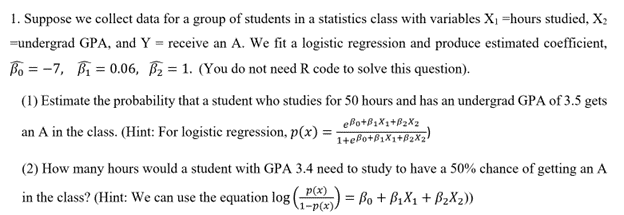


[link text](https://)

Answer: (1) A student who studies 50 hours and has an undergrad GPA of 3.5 has a 37.75% probability to get an A in the class.
(2) A student with a GPA 3.4 needs to study 60 hours to have a 50% chance of getting an A in the class.



3.2 The quantity (p(X))/(1-p(X))is called the odds. Please answer the following questions (You do not need code to solve this question):
(a) On average, what fraction of people with an odds of 0.35 of defaulting on their credit card payment will in fact default?
(b) Suppose that an individual has a 15% chance of defaulting on her credit card payment. What are the odds that she will default?


Answer:(a) On average, approximately 25.93% of people with an odds of 0.35 of defaulting on their credit card payment will default.
(b) If an individul has a 15% chance of defaulting on her credit card payment, the odds that she will default are 0.1765.



3.3 The logistic regression model that results from predicting the probability of default from student status can be seen in the following table. We create a dummy variable that takes on a value of 1 for students and 0 for non-students. Please answer the following questions

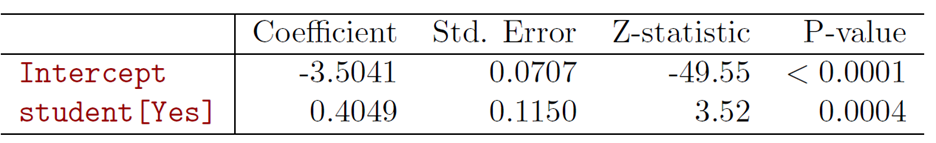

a).How to explain the coefficient before Student[Yes]?
b).If it is a non-student, what are the estimated odds? Is the probability of default less than the probability of not default?


Answer: (a) Student status has a positive and statistically significant relationship with the porbability of default (p<0.0001). Being a student increases the unit of log odds of default by 0.4049. (b) If it's a non-student, the estimated odds are 0.0301, and the probability of default is 2.92% and the probabiltiy of non-default is respectively 97.08%. Therefore the probabiltiy of default is much lower. 

